# Women's clothing reviews, part 1: parsing and cleaning XML data

Parses clothing review records from nested XML into a pandas DataFrame, then audits every column for data quality problems and fixes them, recording each problem and fix in an error log. Part 2 integrates the result with a second dataset.

The data is a version of the [Women's E-Commerce Clothing Reviews](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews) dataset that was modified with deliberate errors for a data-cleaning exercise. It is not included in this repository; see the README.

Environment: Python 3 and Jupyter notebook

Libraries used:
* pandas
* re
* numpy
* xml
* itertools
* lxml
* matplotlib
* sklearn

## Introduction

This project involved parsing data from an XML file into a pandas DataFrame, cleaning that data, then merging it with another DataFrame (in part 2). The first problem was that two elements, section and department, were nested in the XML file. This was overcome by extracting these nested elements and their contents.

The data then needed to be thoroughly cleaned: data types were corrected, and missing values, spelling errors, outliers and impossible values were all handled.

Every action taken to clean the data was recorded in a separate error log. This keeps track of all changes made, and also of findings that were deliberately left unchanged.

The outputs are two CSV files: the clean dataset, and the error log with details of what was found and changed.

## Importing libraries 

In [1]:
import pandas as pd
import numpy as np
import re
import xml.etree.ElementTree as eltree
from itertools import chain
from lxml import etree 
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

## 1. Parsing data

### 1.1. Examining and loading data
The xml data is loaded into the python notebook using eltree.parse(). The dataset is found to have 11 elements with 2 of those being nested. Code has been adapted from course materials on parsing XML [1].

In [2]:
# Load the data
tree = eltree.parse("data/reviews_dataset1.xml")

# Get the root element
root = tree.getroot()
root.tag

'Clothes'

In [3]:
# How many records are contained in the xml file?
len(root)

6406

In [4]:
# By looping through the children of the root node, we can see there are 10 elements, we are expecting 11 and not expecting 'store', but expecting Section and Department 
for child in root[0]:
    print(child)

<Element 'Store' at 0x110ffae30>
<Element 'ClothID' at 0x15ce0ab10>
<Element 'Age' at 0x15ce0ab60>
<Element 'Review_Title' at 0x15ce0abb0>
<Element 'Customer_Rating' at 0x15ce0ac00>
<Element 'Recommended_IND' at 0x15ce0ac50>
<Element 'Positive_Review_Count' at 0x15ce0acf0>
<Element 'Category' at 0x15ce0ad40>
<Element 'Online_Time' at 0x15ce0ad90>
<Element 'Cost' at 0x15ce0ae30>


In [5]:
# This also confirms there are 10 elements. 
len(root[0])

10

This indicates that department and section must be nested elements. This can be confirmed by observing the xml file visually.

In [6]:
# return the unique elements for the first clothing item review
set([child.tag for child in root[0]])

{'Age',
 'Category',
 'ClothID',
 'Cost',
 'Customer_Rating',
 'Online_Time',
 'Positive_Review_Count',
 'Recommended_IND',
 'Review_Title',
 'Store'}

In [7]:
# View all the elements for every clothing item review
set(chain.from_iterable([[child.tag for child in root[i]] for i in range(0, len(root))]))

{'Age',
 'Category',
 'ClothID',
 'Cost',
 'Customer_Rating',
 'Online_Time',
 'Positive_Review_Count',
 'Recommended_IND',
 'Review_Title',
 'Store'}

In [ ]:
# using the iter() function, iterating over the the children of each node we are now unpacking the 
# structure of the xml file. We can now see the nested elements we were expecting to see, section and department.
# We can also see there is no data stored in Store.
for elem in tree.iter():
    print (elem.tag, elem.text, elem.attrib)

In [ ]:
# parsing the data again for furhter inspection. We can use the xpath() function combined with 
# the axis selector 'descendant-or-self::text()' which discards any unrelated, unuseful data. 
# This allows us to unpack the data points for each element.
ltree = etree.parse("data/reviews_dataset1.xml")
for el in ltree.xpath('descendant-or-self::text()'):
    print(el)

### 1.2 Parsing data into the required format
In order to parse the xml file, code was adapted from this youtube video [2].

In [10]:
# Initialise an empty list which will be filled with the elements and data from our xml file
df = []

# Create a function to parse the XML file into a DataFrame
def parse_element(element, item):  # Function takes two inputs: the current XML element and a dictionary to store data.
    
    if len(list(element)) == 0:  # If the element has no child elements (i.e., it's a leaf node in the XML tree).
        item[element.tag] = element.text  # Store the text content of the element in the dictionary with the element's tag as the key.
        
    else:  # If the element has child elements.
        for child in list(element):  # Iterate over each child element.
            parse_element(child, item)  # Recursively call parse_element on the child element, passing the same dictionary.


In [11]:
#Iterate through the xml tree and parse the elements using the previously defined function
for child in root:
    item = {}
    parse_element(child, item)
    df.append(item)

In [12]:
# Convert the variable df from list to a dataframe. 
df = pd.DataFrame(df)
df

,Section,Department,ClothID,Age,Review_Title,Customer_Rating,Recommended_IND,Positive_Review_Count,Category,Online_Time,Cost
0,General Petite,Bottoms,473.0,36,Lovely,4.0,1,0.0,Pants,9.69176321881794,92.94142630541882
1,General,Tops,872.0,37,Adorbs,5.0,1,3.0,Knits,9.454768573743257,103.10916417449265
2,General Petite,Tops,829.0,35,Go to top,5.0,1,0.0,Blouses,4.909755992415713,26.700779829180718
3,General,Dresses,1081.0,37,Snag rag!,1.0,0,1.0,Dresses,56.430229124769575,139.53608082066634
4,General Petite,Tops,906.0,35,"Love, love, love",5.0,1,0.0,Fine gauge,5.4422280758404735,52.92766159912938
...,...,...,...,...,...,...,...,...,...,...,...
6401,General,Dresses,1098.0,54,Sassy maxi,5.0,1,0.0,Dresses,10.447440401221343,87.42100024228615
6402,General,Dresses,1081.0,34,Beautiful plaid material,4.0,1,0.0,Dresses,11.800246514899387,147.2143519495114
6403,General,Tops,872.0,31,Not ideal,3.0,0,0.0,Knits,20.3731503677973,69.61520478559507
6404,General,Tops,895.0,40,Cute and cozy,3.0,1,0.0,Fine gauge,5.339301053657033,44.508626245644855


The dataframe is now built, however the columns need to be rearranged into the target order. I have followed this approach from source [3].

In [13]:
# Rearrange columns
df = df.loc[:, ['ClothID', 'Age', 'Review_Title', 'Customer_Rating', 
                'Positive_Review_Count', 'Section', 'Department', 
                'Category', 'Online_Time', 'Cost', 'Recommended_IND']]
df

,ClothID,Age,Review_Title,Customer_Rating,Positive_Review_Count,Section,Department,Category,Online_Time,Cost,Recommended_IND
0,473.0,36,Lovely,4.0,0.0,General Petite,Bottoms,Pants,9.69176321881794,92.94142630541882,1
1,872.0,37,Adorbs,5.0,3.0,General,Tops,Knits,9.454768573743257,103.10916417449265,1
2,829.0,35,Go to top,5.0,0.0,General Petite,Tops,Blouses,4.909755992415713,26.700779829180718,1
3,1081.0,37,Snag rag!,1.0,1.0,General,Dresses,Dresses,56.430229124769575,139.53608082066634,0
4,906.0,35,"Love, love, love",5.0,0.0,General Petite,Tops,Fine gauge,5.4422280758404735,52.92766159912938,1
...,...,...,...,...,...,...,...,...,...,...,...
6401,1098.0,54,Sassy maxi,5.0,0.0,General,Dresses,Dresses,10.447440401221343,87.42100024228615,1
6402,1081.0,34,Beautiful plaid material,4.0,0.0,General,Dresses,Dresses,11.800246514899387,147.2143519495114,1
6403,872.0,31,Not ideal,3.0,0.0,General,Tops,Knits,20.3731503677973,69.61520478559507,0
6404,895.0,40,Cute and cozy,3.0,0.0,General,Tops,Fine gauge,5.339301053657033,44.508626245644855,1


## 2. Auditing and cleansing the loaded data

In [14]:
# Create error recorder
error_cols = ['datasetNo','indexOfdf', 'Id', 'ColumnName', 'Original','Modified', 'ErrorType', 'Fixing']
erlist = pd.DataFrame(columns=error_cols)

In [15]:
# Function to update the error list
def updateErlist(datasetNo, indexOfdf = [], Id = [], ColumnName = [], Original = [], Modified = [], ErrorType = [], Fixing = []):
    errItem=[datasetNo, indexOfdf, Id, ColumnName, Original, Modified, ErrorType, Fixing]
    erlist.loc[len(erlist)]=errItem

The error list implementation has been adapted from course materials on data cleaning [4]. 

In [16]:
#Check empty dataframe for errors
erlist

,datasetNo,indexOfdf,Id,ColumnName,Original,Modified,ErrorType,Fixing


In [17]:
#Inspect shape of df
df.shape

(6406, 11)

In [18]:
#Inspect first 5 rows
df.head()

,ClothID,Age,Review_Title,Customer_Rating,Positive_Review_Count,Section,Department,Category,Online_Time,Cost,Recommended_IND
0,473.0,36,Lovely,4.0,0.0,General Petite,Bottoms,Pants,9.69176321881794,92.94142630541882,1
1,872.0,37,Adorbs,5.0,3.0,General,Tops,Knits,9.454768573743257,103.10916417449265,1
2,829.0,35,Go to top,5.0,0.0,General Petite,Tops,Blouses,4.909755992415713,26.700779829180718,1
3,1081.0,37,Snag rag!,1.0,1.0,General,Dresses,Dresses,56.430229124769575,139.53608082066634,0
4,906.0,35,"Love, love, love",5.0,0.0,General Petite,Tops,Fine gauge,5.4422280758404735,52.92766159912938,1


In [19]:
#Inspect columns, data types, missing values
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6406 entries, 0 to 6405
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ClothID                6406 non-null   object
 1   Age                    6406 non-null   object
 2   Review_Title           6406 non-null   object
 3   Customer_Rating        6406 non-null   object
 4   Positive_Review_Count  6406 non-null   object
 5   Section                6406 non-null   object
 6   Department             6406 non-null   object
 7   Category               6406 non-null   object
 8   Online_Time            6406 non-null   object
 9   Cost                   6406 non-null   object
 10  Recommended_IND        6406 non-null   object
dtypes: object(11)
memory usage: 550.6+ KB


ClothID                  0
Age                      0
Review_Title             0
Customer_Rating          0
Positive_Review_Count    0
Section                  0
Department               0
Category                 0
Online_Time              0
Cost                     0
Recommended_IND          0
dtype: int64

In [20]:
# Change data type for clothing ID to integer
df['ClothID'] = df['ClothID'].astype(float).astype(int)

In [21]:
# Update error list
updateErlist('dataset1', 'ALL', 'ALL', 'ClothID', 'ALL', 'ALL', 'Incorrect data type', 'Converted from Object to Integer as ClothID can only be an int value.')

In [22]:
# Inspect Age Column
df['Age'].value_counts()

39    360
35    233
46    225
38    217
34    212
     ... 
4       1
81      1
86      1
92      1
89      1
Name: Age, Length: 76, dtype: int64

In [23]:
# Can see a list of ages, lets inspect further, in order to do this, we need to convert the column to an integer.
df['Age'] = df['Age'].astype(int)

In [24]:
# Update error list
updateErlist('dataset1', 'ALL', 'ALL', 'Age', 'ALL', 'ALL', 'Incorrect data type', 'Converted from Object to Integer as Age can only be an int value.')

In [25]:
# Descriptive statistics show the min age of a reviewer is 2 years old and the max is 99. The average age is 43
df['Age'].describe()

count    6406.000000
mean       43.267874
std        12.291873
min         2.000000
25%        34.000000
50%        41.000000
75%        52.000000
max        99.000000
Name: Age, dtype: float64

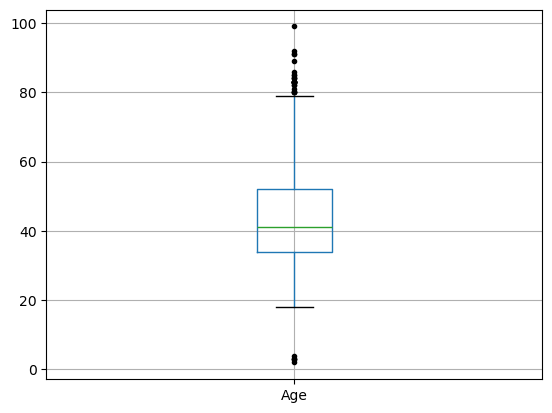

In [26]:
# Plot shows outliers with some elderly people leaving reviews.
# Those are possibly genuine review however there are some data points below the lower whisker.. 
# Lets veiw those...
boxplot = df.boxplot(column = 'Age', sym = 'k.')
plt.show()

In [27]:
# Filter rows where Age is less than 16
df_under_16 = df[df['Age'] < 16]

# Display the filtered DataFrame - It is high unlikely that a 2-4 year old has left a review on a clothing
# Therefore we will replace these values with the median value
# Outliers found on the top end appear to be genuine reviews so will be left as is.
df_under_16

,ClothID,Age,Review_Title,Customer_Rating,Positive_Review_Count,Section,Department,Category,Online_Time,Cost,Recommended_IND
193,1081,3,Shapeless,3.0,1.0,General,Dresses,Dresses,8.104808547750388,58.09480132523876,0
1501,167,3,Almost perfect... check sizing!,5.0,1.0,General,Bottoms,Shorts,4.117435340075524,42.7434464492861,1
2550,1094,3,Cute outfit,4.0,2.0,General,Dresses,Dresses,5.715172353178944,100.94704029260454,1
3915,1066,4,Too flare,2.0,1.0,General,Bottoms,Pants,22.442174538558646,41.96040601297482,0
4181,1080,2,Not too spicy,4.0,1.0,General,Dresses,Dresses,6.2342704218818845,131.11874455659057,1


I have filtered the dataframe to show reviews left by those younger than 16. I chose 16 as it looks slightly less than the lower whisker in the boxplot. We can see there is 5 records where the age of the reviewer is listed as between 2-4 years old. These are considered as impossible values, possibly caused by typos or intentionally inaccurate inputs by users. In order to fix this, the median age value will be imputed [5]. 


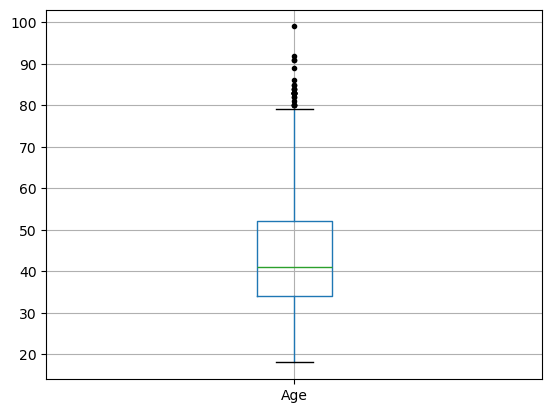

In [28]:
# Calculate the median age for valid ages (>16 years old)
median_age = df[df['Age'] >= 16]['Age'].median()

# Replace ages less than 16 with the median age
df.loc[df['Age'] < 16, 'Age'] = median_age

# Plot to ensure these impossible values are removed.
boxplot = df.boxplot(column = 'Age', sym = 'k.')
plt.show()

We can see from the boxplot that those data points with ages 2-4 have been updated. There are also some outliers aged 80 and over who have left reviews. These cannot be considered impossible values. In fact these values must be considered genuine without any evidence otherwise. Removing these outliers, or imputing them with any number would cause bias against elderly people in the data. These data points will be left as they are. If performing any kind of machine learning that relies on data that has a normal distribution, data transformation may be an appropriate way of handling the skewness of the Age variable, however that is outside the scope of this cleaning stage, so the data will be left as it is.

In [29]:
# Create variables to add to error list
id = df_under_16.ClothID
index = id.index
old_vals = df_under_16.Age

# Loop over error rows to add to error list
for i in range(len(index)):
    updateErlist('dataset1', index[i], id.iloc[i], 'Age', old_vals.iloc[i], f'Median of valid ages {median_age}', 'Impossible value', 'Imputed median value')


In [30]:
# Calculate upper bound for age
Q3 = df['Age'].quantile(0.75)
Q1 = df['Age'].quantile(0.25)
IQR = Q3 - Q1

# Calculate the upper bound for outliers - People older than 79 are 'Outliers' - 
upper_bound = Q3 + 1.5 * IQR
print(upper_bound)

# Filter rows where Age is less than 16
df_over_79 = df[df['Age'] >= 79]

# Create variables to add to error list
id = df_over_79.ClothID
index = id.index
old_vals = df_over_79.Age

79.0


The above code block is for the purpose of completing the erList.

In [31]:
# Loop over error rows to add to error list
for i in range(len(index)):
    updateErlist('dataset1', index[i], id.iloc[i], 'Age', old_vals.iloc[i], ' ', 'Outliers', 'Left as they likely represent real values')

In [32]:
# Inspect Review title column
df['Review_Title'].value_counts()

Love it!                        49
Beautiful                       35
Love                            34
Love!                           27
Beautiful!                      23
                                ..
Work and play                    1
Order a size up!                 1
Versitile tank                   1
Cute, lightweight summer top     1
Cute and cozy                    1
Name: Review_Title, Length: 5103, dtype: int64

It can be seen that there are 5103 review titles, indicating possible duplicate reviews. However, it is possible a customer could copy a review title from another customer. Duplicates will be checked for after initial pass of all columns. It is not possible to 'clean' this column, as it is text based user input, and there is no specific business rules to indicate any required resolution with this variable. This column will be left as it is.

In [33]:
# Check customer_rating column - first probelm is the data type - needs to be changed from object to int
df['Customer_Rating']

0       4.0
1       5.0
2       5.0
3       1.0
4       5.0
       ... 
6401    5.0
6402    4.0
6403    3.0
6404    3.0
6405    5.0
Name: Customer_Rating, Length: 6406, dtype: object

In [34]:
# Can also see here that two ratings contain impossible values of 5.25
df['Customer_Rating'].value_counts()

5.0     3541
4.0     1403
3.0      810
2.0      416
1.0      234
5.25       2
Name: Customer_Rating, dtype: int64

In [35]:
# View the records where the impossible 'Customer Rating' exists.
df_cr_525 = df[df['Customer_Rating'] == '5.25']
df_cr_525

,ClothID,Age,Review_Title,Customer_Rating,Positive_Review_Count,Section,Department,Category,Online_Time,Cost,Recommended_IND
1939,829,32,Perfect fall tunic!,5.25,4.0,General,Tops,Blouses,13.447177896021106,22.34244676095886,1
3198,860,43,Super soft and sweet,5.25,2.0,General Petite,Tops,Knits,7.667489715585189,41.09959835610561,1


In [36]:
# Lets try doing conversion to see if all information is retained 
df['Customer_Rating'] = df['Customer_Rating'].astype(float).astype(int)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6406 entries, 0 to 6405
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ClothID                6406 non-null   int64 
 1   Age                    6406 non-null   int64 
 2   Review_Title           6406 non-null   object
 3   Customer_Rating        6406 non-null   int64 
 4   Positive_Review_Count  6406 non-null   object
 5   Section                6406 non-null   object
 6   Department             6406 non-null   object
 7   Category               6406 non-null   object
 8   Online_Time            6406 non-null   object
 9   Cost                   6406 non-null   object
 10  Recommended_IND        6406 non-null   object
dtypes: int64(3), object(8)
memory usage: 550.6+ KB


In [37]:
# Update Error List
updateErlist('dataset1', 'ALL', 'ALL', 'Customer Rating', 'ALL', 'ALL', 'Incorrect data type', 'Converted from object to int' )

In [38]:
# Can see that we have not lost any data by doing this as length of df is still 6406
df['Customer_Rating']

0       4
1       5
2       5
3       1
4       5
       ..
6401    5
6402    4
6403    3
6404    3
6405    5
Name: Customer_Rating, Length: 6406, dtype: int64

In [39]:
# Can see now that those 5.25 reviews have been added to '5'
df['Customer_Rating'].value_counts()

5    3543
4    1403
3     810
2     416
1     234
Name: Customer_Rating, dtype: int64

In [40]:
#Update Error List
updateErlist('dataset1', 1939, 829, 'Customer Rating', 5.25, 5, 'Impossible Value', 'Round down to nearest int value as most logical option' )
updateErlist('dataset1', 3198, 860, 'Customer Rating', 5.25, 5, 'Impossible Value', 'Round down to nearest int value as most logical option' )

Some trial and error was used to see the behaviour of changing a data type from float to int and what would happen with the 5.25 values. I did initially change these manually from 5.25 to 5, however when noticing that the conversion from float to int automatically adjusted those values into their correct form, I decided to run with that. Admittedly, care does need to be taken when using such an approach in order to avoid loss of data.

In [41]:
# Inspect Positive_Review_Count
df['Positive_Review_Count'].value_counts()


0.0     2853
1.0     1156
2.0      623
3.0      446
4.0      253
5.0      192
6.0      173
7.0      119
8.0       81
10.0      64
11.0      61
9.0       55
12.0      42
14.0      34
13.0      33
17.0      30
15.0      24
16.0      21
18.0      16
19.0      14
20.0      14
25.0      12
21.0      11
23.0       8
29.0       6
31.0       5
24.0       5
30.0       5
26.0       4
22.0       4
0.5        4
81.0       3
32.0       3
27.0       2
39.0       2
33.0       2
37.0       2
36.0       2
40.0       2
51.0       2
47.0       1
50.0       1
95.0       1
42.0       1
38.0       1
48.0       1
28.0       1
94.0       1
49.0       1
46.0       1
43.0       1
53.0       1
45.0       1
44.0       1
3.5        1
57.0       1
34.0       1
84.0       1
Name: Positive_Review_Count, dtype: int64

In [42]:
# Update the data type of positive review count to int
df['Positive_Review_Count'] = df['Positive_Review_Count'].astype(float).astype(int)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6406 entries, 0 to 6405
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ClothID                6406 non-null   int64 
 1   Age                    6406 non-null   int64 
 2   Review_Title           6406 non-null   object
 3   Customer_Rating        6406 non-null   int64 
 4   Positive_Review_Count  6406 non-null   int64 
 5   Section                6406 non-null   object
 6   Department             6406 non-null   object
 7   Category               6406 non-null   object
 8   Online_Time            6406 non-null   object
 9   Cost                   6406 non-null   object
 10  Recommended_IND        6406 non-null   object
dtypes: int64(4), object(7)
memory usage: 550.6+ KB


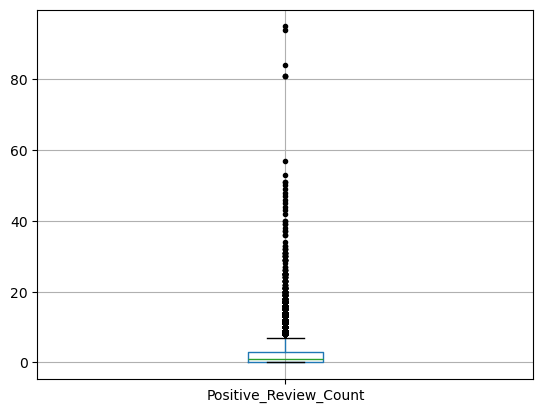

In [43]:
# Plot to ensure these impossible values are removed.
boxplot = df.boxplot(column = 'Positive_Review_Count', sym = 'k.')
plt.show()

There are numerous outliers here. Considering that this variable is the number of customers who found the review positive, it is valuable information. By addressing outliers with imputation or removal here, would be to remove significant possibility of insight from this variable. Similar to the age variable for those older than 79, these outliers will be kept, as removing them or imputing values would be detrimental. If dealing with outliers was essential for further analysis, data transformation could be used to normalise the data while maintaining data integrity. Data transformation is outside the scope of this cleaning stage.

In [44]:
# Update Error List for change of data type
updateErlist('dataset1', 'ALL', 'ALL', 'Positive_Review_Count', 'ALL', 'ALL', 'Incorrect data type', 'Converted Object to Integer, as it is a count and can only hold integer values.')
# Update Error List for outliers detected but not removed
updateErlist('dataset1', 'Positive_Review_Count outliers', 'Positive_Review_Count outliers', 'Positive_Review_Count', 'ALL', 'ALL', 'Outliers', 'Left them in place, as imputing or removing them could be detrimental to data integrity. Data transformation may be a more suitable approach to dealing with these outliers.')

In [45]:
# Inspect section - Appears to not require any cleaning
df['Section'].value_counts()

General           3820
General Petite    2187
Initmates          399
Name: Section, dtype: int64

The 'Section' variable contains three 'sections'. This variable appears to be satisfactory. Without specific instructions or domain knowledge, this column will be left as is.

In [46]:
# Inspect Department - Appears to not require any cleaning
df['Department'].value_counts()

Tops        2872
Dresses     1740
Bottoms     1031
Intimate     460
Jackets      265
Trend         38
Name: Department, dtype: int64

The 'Department' variable contains six 'departments'. This variable appears to be satisfactory. Without specific instructions or domain knowledge, this column will be left as is.

In [47]:
# Inspect Category - Appears to be some spelling errors
df['Category'].value_counts()

Dresses           1740
Knits             1328
Blouses            884
Pants              389
Sweaters           377
Jeans              318
Fine gauge         282
Skirts             247
Lounge             177
Jackets            172
Swim                99
Outerwear           92
Shorts              75
Sleep               53
Intimates           50
Layering            41
Legwear             39
Trend               38
Jacktes              1
Kints                1
kSirts               1
Chemises             1
Casual bottoms       1
Name: Category, dtype: int64

As seen above, there are some obvious spelling errors, lets find them... 

In [48]:
# Find records with identified spelling errors
category_mispelled = df[df['Category'].isin(['Jacktes', 'Kints', 'kSirts'])]
category_mispelled

,ClothID,Age,Review_Title,Customer_Rating,Positive_Review_Count,Section,Department,Category,Online_Time,Cost,Recommended_IND
915,975,55,Disappointed,2,1,General,Jackets,Jacktes,30.806020698344067,95.85061057837368,0
4064,867,44,Absolutely adorable,5,3,General Petite,Tops,Kints,13.750941658797627,36.93533767950931,1
4915,999,39,Love it!,5,0,General Petite,Bottoms,kSirts,3.2618306197901985,54.71956832120173,1


In [49]:
# Update values to correct values - these appear to be simple spelling errors
replace_dict = {"Jacktes": "Jackets", "Kints": "Knits", "kSirts": "Skirts"}
df.Category.replace(replace_dict, inplace=True)
df['Category'].value_counts()


Dresses           1740
Knits             1329
Blouses            884
Pants              389
Sweaters           377
Jeans              318
Fine gauge         282
Skirts             248
Lounge             177
Jackets            173
Swim                99
Outerwear           92
Shorts              75
Sleep               53
Intimates           50
Layering            41
Legwear             39
Trend               38
Chemises             1
Casual bottoms       1
Name: Category, dtype: int64

Code above adapted from course materials on data cleaning [4]. There does appear to be some overlap with various categories EG jeans, pants, legwear, shorts. However without domain knowledge or instruction from the data supplier/client, it is not possible to clean this variable any further. 

In [50]:
#Update Error List
updateErlist('dataset1', 915, 975, 'Category', 'Jacktes', 'Jackets', 'Mispelling/Typo', 'Updated the incorrect values with the correct spelling')
#Update Error List
updateErlist('dataset1', 4064, 867, 'Category', 'Kints', 'Knits', 'Mispelling/Typo', 'Updated the incorrect values with the correct spelling')
#Update Error List
updateErlist('dataset1', 4915, 999, 'Category', 'kSirts', 'Skirts', 'Mispelling/Typo', 'Updated the incorrect values with the correct spelling')

In [51]:
# Inspect 'Online_Time' column
df['Online_Time'].value_counts()

9.69176321881794      1
7.152918785508004     1
7.6315001932073345    1
3.821186386676804     1
4.431311119544387     1
                     ..
16.76056568763567     1
14.166178733859926    1
4.940700030201112     1
7.496762230190932     1
8.340926276208286     1
Name: Online_Time, Length: 6406, dtype: int64

In [52]:
#Convert data type to float and round to 3 decimal places
df['Online_Time'] = round(df['Online_Time'].astype(float), 3)

Consideration was given to using regular expression to convert the column to values that read like "9 minutes 40 seconds". This may have made the data more readable for a user, but potentially made it more difficult for analysis. Regardless, when this dataset is merged with the second one, the second dataset's schema is adopted. Therefore, there would be no point in adding that level of complexity to this notebook, so the data was left as a floating point.

In [53]:
#Update error list
updateErlist('dataset1', 'ALL', 'ALL', 'Online_Time', 'ALL', 'ALL', 'Incorrect data type', 'Converted from object to Float' )
updateErlist('dataset1', 'ALL', 'ALL', 'Online_Time', 'ALL', 'ALL', 'Long floating point number', 'Rounded to 3 decimals' )

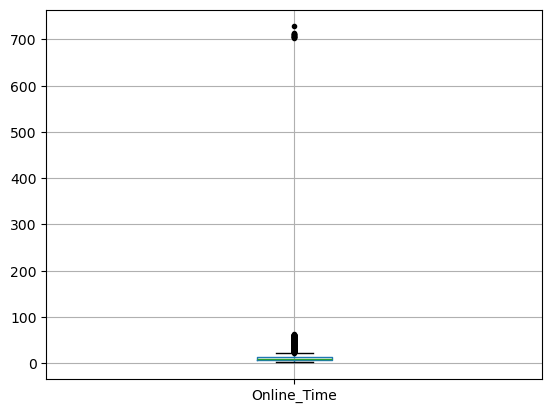

In [54]:
# Check Online Time for Outliers
boxplot = df.boxplot(column = 'Online_Time', sym = 'k.')
plt.show()

Can see several outliers particularly those spending >700 minutes. This suggests a user took 700 minutes to write a review. Whilst that is possible, it is highly unlikely, and it is seriously skewing the data. Therefore we will treat those extreme values as outliers and do some imputation.

In [55]:
# Filter rows where Online Time is > 650
df_ot_outliers = df[df['Online_Time'] > 650]

# Display records of outliers.
df_ot_outliers 

,ClothID,Age,Review_Title,Customer_Rating,Positive_Review_Count,Section,Department,Category,Online_Time,Cost,Recommended_IND
322,863,39,So cute!,5,0,General Petite,Tops,Knits,710.584,76.40392234815147,1
399,1095,41,Gorgeous dress!,5,0,General Petite,Dresses,Dresses,706.162,51.203735802022,1
1363,1080,28,Fun and comfy,4,6,General Petite,Dresses,Dresses,712.308,84.56927706572618,1
2221,936,26,Pretty but not what i was looking for.,3,1,General,Tops,Sweaters,711.097,71.32166335756158,0
2355,1020,27,Size up!,4,1,General Petite,Bottoms,Skirts,710.685,47.264078581669494,1
2408,1094,56,Stunning,5,11,General,Dresses,Dresses,707.210,65.32315715928767,1
2424,185,36,Warm and attractive but too tight/narrow and s...,2,1,Initmates,Intimate,Legwear,728.258,121.68885110537252,0
2466,815,26,Pretty back,3,0,General,Tops,Blouses,705.024,48.82544967431308,1
2939,952,54,A mixed bag,3,0,General,Tops,Sweaters,705.897,73.85987236070831,0
3093,949,83,Scottish classic,5,0,General,Tops,Sweaters,713.363,47.45120436272062,1


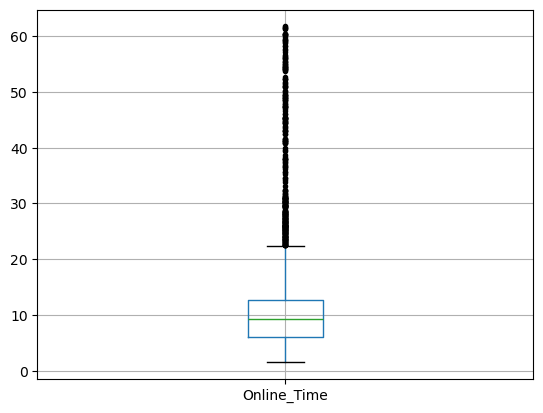

In [56]:
# Calculate the median Online Time for those excluding those LARGE outliers
median_ot = df[df['Online_Time'] < 650]['Online_Time'].median()

# Replace LARGE outliers with the median age
df.loc[df['Online_Time'] > 650, 'Online_Time'] = median_ot

# Plot to ensure these impossible values are removed.
boxplot = df.boxplot(column = 'Online_Time', sym = 'k.')
plt.show()

The median has been used to impute for the detected extreme values outliers. The median was chosen as the data (excluding the extreme values) appears to be positively skewed, so the median is a better measure of central tendancy. Again from the boxplot above, there are still numerous outliers ranging from about 23 minutes to about 62 minutes. The density of outliers appears quite high closer to the top end whikser. Without deeper domain knowledge or advice from stakeholders, these data points must be considered genuine and imputation for these will be detrimnetal for data integrity. Instead, data transformation can be implemented for normalisation. 

In [57]:
# Create variables to add to error list
index = df_ot_outliers.index
id = df_ot_outliers.ClothID
old_vals = df_ot_outliers.Online_Time

# Loop over error rows to add to error list
for i in range(len(index)):
    updateErlist('dataset1', index[i], id.iloc[i], 'Online_Time', old_vals.iloc[i], median_ot, 'Outliers', 'Imputed median because these values greater than 700 minutes were extreme and likely erroneous.')

In [58]:
# Inspect 'Cost' column
df['Cost'].value_counts()

-1.0                  8
92.94142630541882     1
35.610361026525325    1
69.73720293701396     1
77.37515146089027     1
                     ..
99.18787893184542     1
41.524698299453156    1
53.24232228415529     1
113.48861319824898    1
62.74039647091736     1
Name: Cost, Length: 6399, dtype: int64

In [59]:
#Convert data type and round to 3 decimal places
df['Cost'] = round(df['Cost'].astype(float), 3)

In [60]:
#Update error list
updateErlist('dataset1', 'ALL', 'ALL', 'Cost', 'ALL', 'ALL', 'Incorrect data type', 'Converted from object to Float' )
updateErlist('dataset1', 'ALL', 'ALL', 'Cost', 'ALL', 'ALL', 'Long floating point number', 'Rounded to 3 decimals' )

In [61]:
# View the column value counts for Cost - Can see 8 items have a cost of -1.
df.Cost.value_counts()

-1.000      8
 60.572     3
 45.676     3
 62.705     3
 41.517     3
           ..
 77.901     1
 49.431     1
 87.889     1
 110.832    1
 62.740     1
Name: Cost, Length: 6188, dtype: int64

In [62]:
# The summary statistics... We can see the min = -1 which is impossible. Lets investigate further.
df['Cost'].describe()

count    6406.000000
mean       76.711400
std        31.978351
min        -1.000000
25%        51.260250
50%        71.700500
75%        99.149250
max       179.504000
Name: Cost, dtype: float64

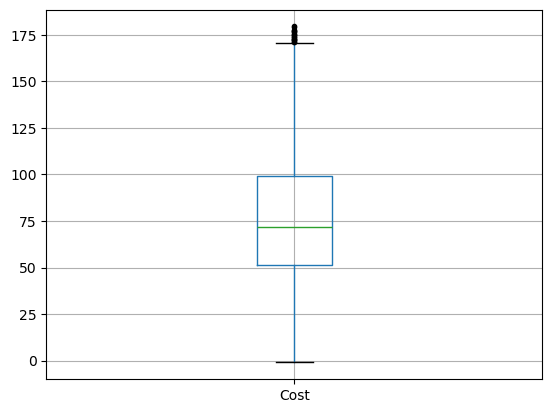

In [63]:
# Visualise cost
boxplot = df.boxplot(column = 'Cost', sym = 'k.')
plt.show()

In [64]:
# Set outliers (-1) to NaN 
df.loc[(df.Cost < 0), 'Cost'] = np.NaN

In [65]:
# Filter the NaN values out 
df_dropna = df.loc[~np.isnan(df.Cost),]
df_dropna

,ClothID,Age,Review_Title,Customer_Rating,Positive_Review_Count,Section,Department,Category,Online_Time,Cost,Recommended_IND
0,473,36,Lovely,4,0,General Petite,Bottoms,Pants,9.692,92.941,1
1,872,37,Adorbs,5,3,General,Tops,Knits,9.455,103.109,1
2,829,35,Go to top,5,0,General Petite,Tops,Blouses,4.910,26.701,1
3,1081,37,Snag rag!,1,1,General,Dresses,Dresses,56.430,139.536,0
4,906,35,"Love, love, love",5,0,General Petite,Tops,Fine gauge,5.442,52.928,1
...,...,...,...,...,...,...,...,...,...,...,...
6401,1098,54,Sassy maxi,5,0,General,Dresses,Dresses,10.447,87.421,1
6402,1081,34,Beautiful plaid material,4,0,General,Dresses,Dresses,11.800,147.214,1
6403,872,31,Not ideal,3,0,General,Tops,Knits,20.373,69.615,0
6404,895,40,Cute and cozy,3,0,General,Tops,Fine gauge,5.339,44.509,1


In [66]:
# View the data with NaN values
df_na = df.loc[np.isnan(df.Cost),]
df_na

,ClothID,Age,Review_Title,Customer_Rating,Positive_Review_Count,Section,Department,Category,Online_Time,Cost,Recommended_IND
858,862,53,Great product!,5,2,General,Tops,Knits,10.719,NaN,1
1770,1003,31,"Loved, but returned",4,0,General,Bottoms,Skirts,13.052,NaN,1
4584,1078,38,Odd fit,2,4,General Petite,Dresses,Dresses,15.033,NaN,0
4638,868,32,Almost great,3,2,General,Tops,Knits,10.428,NaN,0
4885,863,29,Comfortable!,4,0,General Petite,Tops,Knits,4.318,NaN,1
4969,1066,42,Love these pants,5,1,General Petite,Bottoms,Pants,3.256,NaN,1
5675,842,52,"Huge, long and baggy",2,0,General Petite,Tops,Blouses,9.791,NaN,0
6119,1126,37,Cutest cape!!!,5,3,General Petite,Jackets,Outerwear,6.119,NaN,1


A couple of approaches have been trialled to deal with these impossible '-1' values. Linear regression is used initially to attempt imputation (adapted from course materials [4]). The results of the predicted linear regression model are poor with an R-squared score of 0.076. A simpler approach was adopted, where for each record with a '-1' (now NaN) value, we look at the records with matching ClothID, then take the mean of the matching clothID and use that for imputation. This approach assumes that items with the same clothID are going to have approximately the same price across different purchases. It is not a perfect approach, however it gives better estimates than the linear regression model.

In [67]:
# Create a dataset for imputation
lm_fitting_df = df_dropna.drop(['Review_Title', 'Section', 'Department', 'Category', 'Recommended_IND'], axis = 1)
lm_fitting_df

,ClothID,Age,Customer_Rating,Positive_Review_Count,Online_Time,Cost
0,473,36,4,0,9.692,92.941
1,872,37,5,3,9.455,103.109
2,829,35,5,0,4.910,26.701
3,1081,37,1,1,56.430,139.536
4,906,35,5,0,5.442,52.928
...,...,...,...,...,...,...
6401,1098,54,5,0,10.447,87.421
6402,1081,34,4,0,11.800,147.214
6403,872,31,3,0,20.373,69.615
6404,895,40,3,0,5.339,44.509


In [68]:
#instatiate another model for imputation purpose
lm_for_impute =  LinearRegression()

In [69]:
#Fit the model - predict Cost using other numerical variables in data set
lm_for_impute.fit(lm_fitting_df[[x for x in lm_fitting_df.columns if x != 'Cost']],lm_fitting_df['Cost']) #fit

LinearRegression()

In [70]:
# Output is 0.076 - A poorly performing model
lm_fitting_X = lm_fitting_df[[x for x in lm_fitting_df.columns if x != 'Cost']]
lm_fitting_y = lm_fitting_df['Cost']
print('r-squared for Cost fitting = ',lm_for_impute.score(lm_fitting_X,lm_fitting_y))

r-squared for Cost fitting =  0.07612026041311815


The Linear Regression model performs poorly for predicting cost. A simpler approach could be taken. To calculate Cost for an item, we will look at other items with same ClothID in the dataset and take the mean cost of those same items and impute it into the missing cost.

In [71]:
#Calculate the mean cost for each item
mean_costs = df_dropna.groupby('ClothID')['Cost'].mean()

In [72]:
# Check mean_costs variable contains desired data
mean_costs

ClothID
1       123.182000
7        91.287000
8        68.949500
9        40.385000
10       50.636000
           ...    
1195     71.477000
1197     78.523000
1198     90.746000
1202     95.796333
1203     82.637333
Name: Cost, Length: 656, dtype: float64

The map function is used to impute costs for matching clothID [6]

In [73]:
# Impute the NaN values in df_na with the corresponding mean costs from mean_costs
df_na['Cost'] = df_na['ClothID'].map(mean_costs)

In [74]:
# Combine the DataFrames
df = pd.concat([df_dropna, df_na])

# Check for any remaining NaN values - Can see no more NaN values or -1 values
print(df['Cost'].isna().sum())

0


The imputed dataframe and the rest of the data are concatenated with concat() [7]

In [75]:
# Display the final dataframe - Can see no more -1 values
df.Cost.describe()

count    6406.000000
mean       76.806023
std        31.867534
min        15.307000
25%        51.400750
50%        71.798000
75%        99.165000
max       179.504000
Name: Cost, dtype: float64

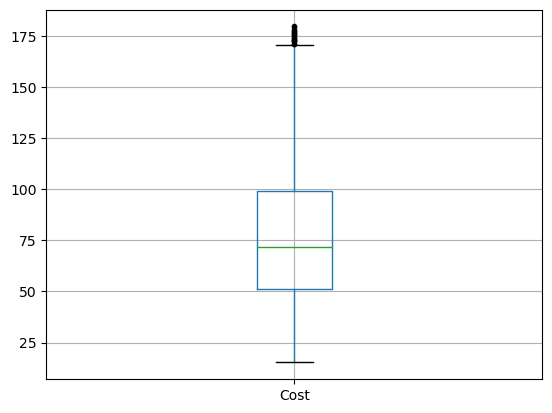

In [76]:
# Visualise final cost column
boxplot = df.boxplot(column = 'Cost', sym = 'k.')
plt.show()

It can be seen in the boxplot and the descriptive statistics that the -1 values are no longer present. The outliers around the 175 mark indicate expensive items, removing or imputing values for these outliers would be inadvisable, as they likely represent real data points. For further analysis data transformation could be used.

In [77]:
#Create variables to update error list
index = df_na.index
id = df_na.ClothID
old_vals = df_na.Cost

# Loop over error rows to add to error list 
for i in range(len(id)):
    clothID = id.iloc[i]
    mean_cost = mean_costs.get(clothID) # [7]
    updateErlist('dataset1', index[i], clothID, 'Cost', -1, mean_cost, 'Outliers/Impossible values', 'Imputed mean of matching ClothID as linear regression model was highly unreliable for prediction.')

In [78]:
#Final column to clean
df.Recommended_IND.value_counts()

1    5240
0    1166
Name: Recommended_IND, dtype: int64

In [79]:
# Convert the 'Recommend_IND' column to boolean type  - first need to change to into, then to bool
df['Recommended_IND'] = df['Recommended_IND'].astype(int).astype(bool)

In [80]:
# Final column to clean
df.Recommended_IND.value_counts()

True     5240
False    1166
Name: Recommended_IND, dtype: int64

In [81]:
# Error list 
updateErlist('dataset1', 'ALL', 'ALL', 'Recommended_IND', 'ALL', 'ALL', 'Incorrect data type', 'Changed from object to boolean')

In [82]:
# Change column names to match the target schema

df.columns = df.columns.str.replace('_', ' ')

In [83]:
# Final check of data frame
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 6406 entries, 0 to 6119
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ClothID                6406 non-null   int64  
 1   Age                    6406 non-null   int64  
 2   Review Title           6406 non-null   object 
 3   Customer Rating        6406 non-null   int64  
 4   Positive Review Count  6406 non-null   int64  
 5   Section                6406 non-null   object 
 6   Department             6406 non-null   object 
 7   Category               6406 non-null   object 
 8   Online Time            6406 non-null   float64
 9   Cost                   6406 non-null   float64
 10  Recommended IND        6406 non-null   bool   
dtypes: bool(1), float64(2), int64(4), object(4)
memory usage: 556.8+ KB


## Saving data

In [84]:
df.to_csv('data/reviews_dataset1_clean.csv', index = False)
erlist.to_csv('error_log.csv', index = False)


## Summary

The XML data was parsed into a pandas DataFrame, and every column was audited and cleaned, with an explanation of each change. All modifications, and findings deliberately left unchanged, are logged in the error list. The clean dataset and the error list are saved as CSV files, ready for integration in part 2.

## References
[1] RMIT University. Advanced Programming for Data Science, course materials on regular expressions and data formats.

[2] Epython Lab. "Transforming Nested XML to Pandas DataFrame" YouTube. [Online]. Available: https://www.youtube.com/watch?v=WQ-OhoXmHU8

[3] R. Chandra, "Pandas reorder columns: Efficient dataframe manipulation techniques", [Online]. Available: https://docs.kanaries.net/topics/Pandas/pandas-reorder-columns

[4] RMIT University. Advanced Programming for Data Science, course materials on data cleaning.

[5] StackOverflow. "Python: replacing outliers values with median values" [Online]. Available: https://stackoverflow.com/questions/45386955/python-replacing-outliers-values-with-median-values

[6] w3schools. "Python map() function" [Online]. Available:https://www.w3schools.com/python/ref_func_map.asp

[7] pandas. "Pandas.concat" [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.concat.html

[8] w3schools. "Python dictionary get() method" [Online]. Available: https://www.w3schools.com/python/ref_dictionary_get.asp
 